Target ($y$): cnt (Jumlah Penyewaan Sepeda)

Fitur ($X$): temp (Suhu),

atemp (Suhu Rasional),

hum (Kelembaban),

windspeed (Kecepatan Angin),

yr (Tahun)

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
path = '/content/drive/MyDrive/MachineLearning/Praktikum01/Data'

df = pd.read_csv(path + '/day.csv')
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [38]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


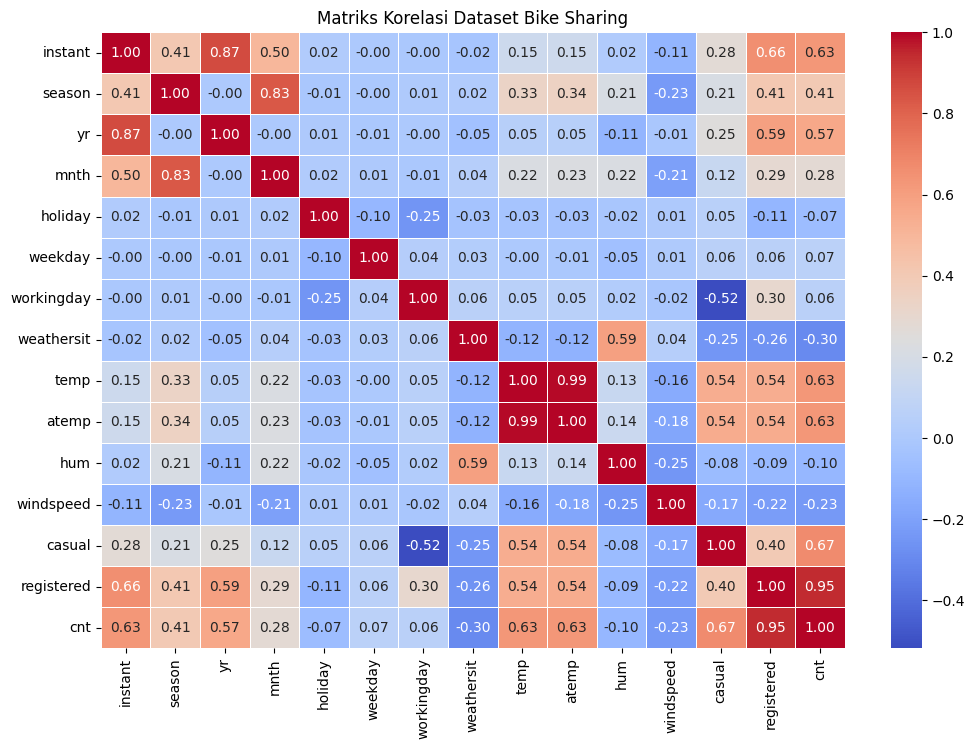

In [39]:
# 1. Menghitung matriks korelasi khusus kolom numerik
corr_matrix = df.corr(numeric_only=True)

# 2. Menampilkan Heatmap Matriks Korelasi
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriks Korelasi Dataset Bike Sharing")
plt.show()

In [40]:
# Target (y) adalah jumlah penyewaan sepeda (cnt) # Variabel dependen
y = df["cnt"]

# Fitur (X) adalah variabel cuaca dan tahun # Variabel independen
X = df[["temp", "atemp", "hum", "windspeed", "yr"]]

# Bagi data 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42 # random_state supaya hasil konsisten
)

#Cetak Pembagian Data
print("Jumlah data train :", len(X_train))
print("Jumlah data test  :", len(X_test))

# Cek data training
X_train.head()

Jumlah data train : 584
Jumlah data test  : 147


,temp,atemp,hum,windspeed,yr
682,0.343333,0.323225,0.662917,0.342046,1
250,0.633913,0.555361,0.939565,0.192748,0
336,0.299167,0.310604,0.612917,0.095783,0
260,0.507500,0.490537,0.695000,0.178483,0
543,0.697500,0.640792,0.360000,0.271775,1


In [41]:
# 1. Menambahkan konstanta ke data train
X_train_const = sm.add_constant(X_train)

# 2. Buat model OLS
model_ols = sm.OLS(y_train, X_train_const).fit()

print('-----------------------------------')
print(model_ols.params)
print('-----------------------------------')

# 3. Parameter / Koefisien
const = model_ols.params['const']
coef_temp = model_ols.params['temp']
coef_atemp = model_ols.params['atemp']
coef_hum = model_ols.params['hum']
coef_wind = model_ols.params['windspeed']
coef_yr = model_ols.params['yr']

# 4. Print persamaan regresi
print(f"y = {const:.3f} + {coef_temp:.3f}*temp + {coef_atemp:.3f}*atemp + {coef_hum:.3f}*hum + {coef_wind:.3f}*windspeed + {coef_yr:.3f}*yr")

# 5. Summary statistik lengkap
print(model_ols.summary())

-----------------------------------
const        2214.845552
temp         2134.857153
atemp        4829.266517
hum         -2161.644125
windspeed   -3630.072363
yr           1980.020947
dtype: float64
-----------------------------------
y = 2214.846 + 2134.857*temp + 4829.267*atemp + -2161.644*hum + -3630.072*windspeed + 1980.021*yr
                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     287.4
Date:                Mon, 28 Sep 2026   Prob (F-statistic):          4.09e-154
Time:                        12:25:26   Log-Likelihood:                -4877.5
No. Observations:                 584   AIC:                             9767.
Df Residuals:                     578   BIC:                             9793.
Df Model:                        

In [42]:
# Tambahkan konstanta ke data uji
X_test_const = sm.add_constant(X_test)

# Prediksi jumlah penyewaan sepeda (cnt)
y_pred_test = model_ols.predict(X_test_const)

# Membuat tabel hasil prediksi
hasil = pd.DataFrame({
    "Temp": X_test["temp"].to_numpy(),
    "Atemp": X_test["atemp"].to_numpy(),
    "Hum": X_test["hum"].to_numpy(),
    "Windspeed": X_test["windspeed"].to_numpy(),
    "Yr": X_test["yr"].to_numpy(),
    "Penyewaan Aktual (cnt)": y_test.to_numpy(),
    "Penyewaan Prediksi (cnt)": y_pred_test.to_numpy()
})

# 1) Selisih error (positif = overpredict)
hasil["Selisih error (cnt)"] = hasil["Penyewaan Prediksi (cnt)"] - hasil["Penyewaan Aktual (cnt)"]

# 2) Akurasi per-baris (100 * (1 - |error|/aktual)), dibatasi 0-100
denom = hasil["Penyewaan Aktual (cnt)"].replace(0, np.nan)  # antisipasi pembagi nol
hasil["Akurasi (%)"] = (1 - (hasil["Selisih error (cnt)"].abs() / denom)).clip(lower=0, upper=1) * 100

hasil

,Temp,Atemp,Hum,Windspeed,Yr,Penyewaan Aktual (cnt),Penyewaan Prediksi (cnt),Selisih error (cnt),Akurasi (%)
0,0.475833,0.469054,0.733750,0.174129,1,6606,5257.681512,-1348.318488,79.589487
1,0.186957,0.177878,0.437826,0.277752,0,1550,1518.308451,-31.691549,97.955384
2,0.330833,0.318812,0.585833,0.229479,0,3747,2361.367027,-1385.632973,63.020204
3,0.425833,0.417287,0.676250,0.172267,1,6041,5031.995747,-1009.004253,83.297397
4,0.550000,0.544179,0.570000,0.236321,1,7538,5907.023875,-1630.976125,78.363278
...,...,...,...,...,...,...,...,...,...
142,0.329167,0.325750,0.594583,0.220775,0,2132,2403.997570,271.997570,87.242140
143,0.794167,0.739275,0.559167,0.200254,0,4258,5544.778086,1286.778086,69.779754
144,0.375000,0.380671,0.643750,0.098896,0,2792,3103.221383,311.221383,88.853102
145,0.626667,0.587754,0.471667,0.167912,0,5180,4762.001882,-417.998118,91.930538


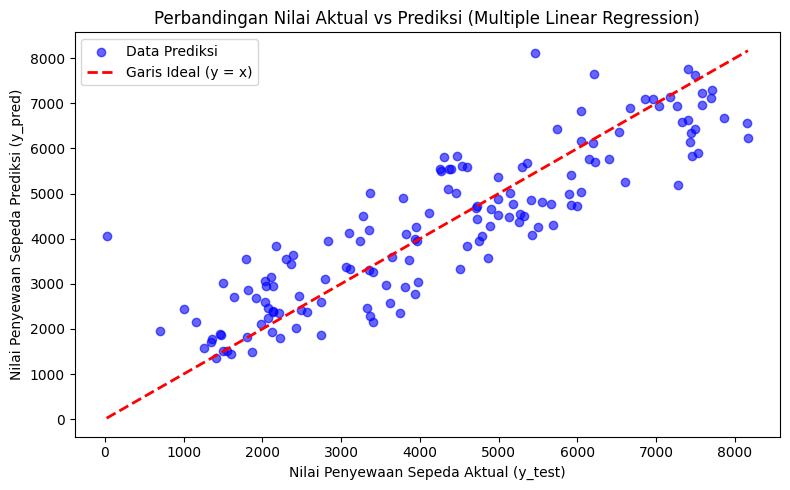

In [43]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_test, color='blue', alpha=0.6, label='Data Prediksi')
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    lw=2,
    label='Garis Ideal (y = x)'
)

plt.xlabel('Nilai Penyewaan Sepeda Aktual (y_test)')
plt.ylabel('Nilai Penyewaan Sepeda Prediksi (y_pred)')
plt.title('Perbandingan Nilai Aktual vs Prediksi (Multiple Linear Regression)')
plt.legend()
plt.tight_layout()
plt.show()

In [44]:
# Prediksi menggunakan data uji (X_test)
y_pred_sklearn = model.predict(X_test)

# Menghitung Metrik Evaluasi
r2 = r2_score(y_test, y_pred_sklearn)
mae = mean_absolute_error(y_test, y_pred_sklearn)
mse = mean_squared_error(y_test, y_pred_sklearn)
rmse = np.sqrt(mse)

print('--- Hasil Evaluasi Model (Scikit-Learn) ---')
print(f'R2 Score : {r2:.4f}')
print(f'MAE      : {mae:.4f}')
print(f'RMSE     : {rmse:.4f}')

--- Hasil Evaluasi Model (Scikit-Learn) ---
R2 Score : 0.7755
MAE      : 747.4321
RMSE     : 948.8022


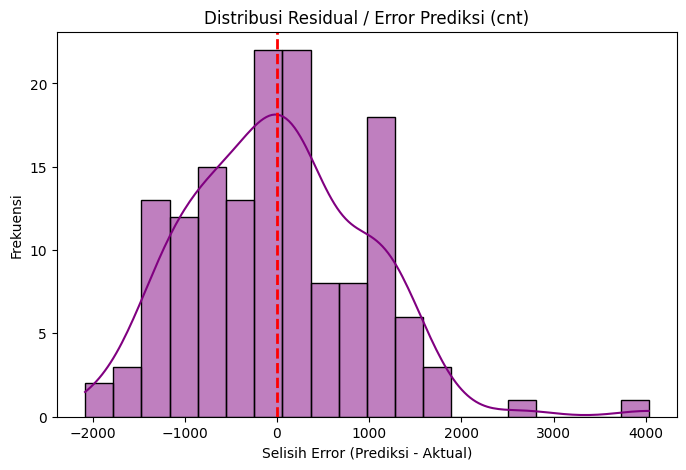

In [46]:
plt.figure(figsize=(8, 5))
sns.histplot(hasil["Selisih error (cnt)"], kde=True, color='purple', bins=20)
plt.axvline(0, color='red', linestyle='--', linewidth=2)
plt.title('Distribusi Residual / Error Prediksi (cnt)')
plt.xlabel('Selisih Error (Prediksi - Aktual)')
plt.ylabel('Frekuensi')
plt.show()

In [31]:
import statsmodels.api as sm
X_train_const = sm.add_constant(X_train)
X_train_const.head()

,const,temp,atemp,hum,windspeed,yr
682,1.0,0.343333,0.323225,0.662917,0.342046,1
250,1.0,0.633913,0.555361,0.939565,0.192748,0
336,1.0,0.299167,0.310604,0.612917,0.095783,0
260,1.0,0.507500,0.490537,0.695000,0.178483,0
543,1.0,0.697500,0.640792,0.360000,0.271775,1


In [34]:
print(model_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     287.4
Date:                Mon, 28 Sep 2026   Prob (F-statistic):          4.09e-154
Time:                        12:02:07   Log-Likelihood:                -4877.5
No. Observations:                 584   AIC:                             9767.
Df Residuals:                     578   BIC:                             9793.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2214.8456    296.318      7.475      0.0

In [45]:
# Menghitung rata-rata akurasi dari tabel hasil
rerata_akurasi = hasil["Akurasi (%)"].mean()
print(f"Rata-rata Akurasi Prediksi Model: {rerata_akurasi:.2f}%")

Rata-rata Akurasi Prediksi Model: 78.57%


## Kesimpulan Praktikum Mandiri

1. **Model Regresi Berganda (Multiple Linear Regression):**
   * Variabel dependen/target ($y$) yang diprediksi adalah **jumlah penyewaan sepeda (`cnt`)**[cite: 5, 9].
   * Variabel independen/fitur ($X$) yang digunakan adalah **`temp`** (suhu), **`atemp`** (suhu rasional), **`hum`** (kelembaban), **`windspeed`** (kecepatan angin), dan **`yr`** (tahun)[cite: 5, 9].

2. **Performa & Evaluasi Model:**
   * Berdasarkan hasil *OLS Regression Results*, model menghasilkan **$R^2$ Score sebesar 0.713 (71.3%)**[cite: 9]. Artinya, sebesar 71.3% variasi jumlah penyewaan sepeda dapat dijelaskan secara bersama-sama oleh variabel cuaca dan tahun[cite: 9].
   * Nilai **F-statistic = 287.4** dengan **Prob (F-statistic) < 0.05** menunjukkan bahwa variabel independen secara simultan berpengaruh signifikan terhadap jumlah penyewaan sepeda[cite: 9].

3. **Pengaruh Variabel Terhadap Penyewaan Sepeda:**
   * **Suhu (`temp`, `atemp`) & Tahun (`yr`):** Berpengaruh positif (semakin hangat suhu dan bertambahnya tahun, jumlah penyewaan sepeda meningkat)[cite: 5].
   * **Kelembaban (`hum`) & Kecepatan Angin (`windspeed`):** Berpengaruh negatif (semakin lembab atau semakin kencang angin, jumlah penyewaan sepeda menurun)[cite: 5].